In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
ART = ROOT / "artifacts"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from plotting import series_styles, new_figure

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

def es(v, d=4):
    """Numero con formato de Colombia: punto de miles y coma decimal."""
    if v is None or (isinstance(v, float) and np.isnan(v)):
        return ""
    if isinstance(v, (int, np.integer)):
        return f"{int(v):,}".replace(",", ".")
    s = f"{float(v):,.{d}f}"
    return s.replace(",", "X").replace(".", ",").replace("X", ".")

def tabla(df, d=4, enteros=()):
    out = df.copy()
    for c in out.columns:
        if c in enteros:
            out[c] = out[c].map(lambda v: es(int(v)) if pd.notna(v) else "")
        elif pd.api.types.is_float_dtype(out[c]):
            out[c] = out[c].map(lambda v: es(v, d))
        elif pd.api.types.is_integer_dtype(out[c]):
            out[c] = out[c].map(es)
    display(out.style.hide(axis="index"))

def figura(ruta, ancho=None):
    display(Image(filename=str(ruta), width=ancho))

# 4. Modelado con scikit-learn

Este capítulo entrena el MLP y sus dos líneas base en scikit-learn {cite}`pedregosa2011scikit` sobre muestras escalonadas de entrenamiento, para construir las curvas de aprendizaje y de costo que pide el enunciado. El propósito es doble: medir cuánto mejora cada modelo con más datos y cuánto cuesta esa mejora en tiempo de cómputo, que es la base de la comparación con Spark de los capítulos 7 y 10.

## 4.1 Diseño experimental

Se entrenan tres modelos con el mismo pipeline de variables (capítulo 3), las mismas particiones y las mismas cinco semillas:

- **SGDClassifier** con pérdida logística, es decir, una regresión logística ajustada por descenso de gradiente estocástico, como línea base lineal.
- **HistGradientBoostingClassifier**, un árbol potenciado por histogramas {cite}`friedman2001greedy,ke2017lightgbm`, como línea base no lineal. Usa solo el bloque denso de frecuencia y target encoding, porque los árboles no aprovechan un espacio disperso de miles de columnas.
- **MLPClassifier** con `early_stopping=True`, optimizado con Adam {cite}`kingma2015adam`, como modelo objetivo.

Los tamaños efectivos de entrenamiento son 80.085, 800.847 y 1.601.694 filas (sección 3.6), y la prueba es la misma muestra fija de 202.511 filas del día 30 para todos los modelos, tamaños y semillas. Esto último es lo que permite comparar los modelos a nivel de instancia en el capítulo 6.

### Búsqueda de hiperparámetros

La búsqueda es bayesiana con Optuna {cite}`akiba2019optuna`, con el muestreador TPE y semilla 13, evaluando cada configuración contra el día 29, tal como exige el enunciado en lugar de `GridSearchCV` con particiones aleatorias. El espacio del MLP es el que fija el enunciado.

| Modelo | Espacio de búsqueda | Ensayos | Muestra de afinación |
|---|---|---|---|
| MLP | `hidden_layer_sizes` en (50,), (100,), (100, 50), (256, 128); `alpha` log-uniforme en $[10^{-5}, 10^{-1}]$; `learning_rate_init` log-uniforme en $[10^{-4}, 10^{-2}]$; `batch_size` en {128, 256, 512} | 10 | unas 160 mil filas |
| SGD | `alpha` log-uniforme en $[10^{-6}, 10^{-2}]$; `penalty` en {l2, elasticnet}; `eta0` log-uniforme en $[10^{-4}, 10^{-1}]$ | 15 | unas 800 mil filas |
| HistGB | `max_depth` en [3, 10]; `learning_rate` log-uniforme en $[0{,}01; 0{,}3]$; `max_leaf_nodes` en [15, 63] | 15 | unas 800 mil filas |

Las muestras de afinación tienen el mismo comportamiento descrito en la sección 3.6: sus tamaños nominales eran 200 mil y 1 millón de filas, y los efectivos son cerca del 80 % de esos valores.

El número de iteraciones del MLP lo controla la parada temprana: hasta 200 épocas, con un 10 % del entrenamiento reservado para detenerse tras 5 épocas sin mejora.

### Ajustes de alcance por tiempo de cómputo medido

La primera ejecución usaba hashing de $2^{14}$ columnas y afinaba el MLP sobre el tier de 1 millón de filas nominales. Medido en esa corrida, un solo ensayo de Optuna del MLP tardaba más de una hora, lo que hacía inviable terminar a tiempo. Se hicieron tres ajustes, todos dentro del margen del enunciado: la dimensión del hashing bajó a $2^{12}$ (es un factor de ablación, no un valor fijo), el MLP se afinó sobre una muestra menor y el tier máximo de entrenamiento quedó en 2 millones de filas nominales, en lugar de 10 millones, lo que el enunciado contempla con la frase "hasta donde permita la memoria". La grilla de arquitecturas y la parada temprana no se tocaron. El historial de ensayos de Optuna no se persistió; solo los mejores parámetros, en `artifacts/sklearn/best_params.json`.

## 4.2 Hiperparámetros seleccionados

In [2]:
bp = json.loads((ART / "sklearn" / "best_params.json").read_text(encoding="utf-8"))
def valor(v):
    if isinstance(v, float):
        return f"{v:.3e}".replace(".", ",") if abs(v) < 0.01 else es(v, 3)
    return str(v)
filas = [(m, k, valor(v)) for m, d in bp.items() for k, v in d.items()]
display(pd.DataFrame(filas, columns=["modelo", "hiperparámetro", "valor"]).style.hide(axis="index"))

modelo,hiperparámetro,valor
sgd,alpha,"3,097e-05"
sgd,penalty,l2
sgd,eta0,"5,551e-03"
histgb,max_depth,10
histgb,learning_rate,"0,112"
histgb,max_leaf_nodes,43
mlp,hidden_layer_sizes,50
mlp,alpha,"3,511e-05"
mlp,learning_rate_init,"2,970e-04"
mlp,batch_size,512


**Interpretación.** Para el MLP, Optuna eligió la arquitectura más pequeña de la grilla, una capa oculta de 50 neuronas, con regularización L2 débil ($\alpha = 3{,}5 \times 10^{-5}$), tasa de aprendizaje inicial de $2{,}97 \times 10^{-4}$ y lotes de 512. HistGB eligió árboles de profundidad 10 con 43 hojas y una tasa de aprendizaje de 0,112, y SGD una penalización L2 con $\alpha = 3{,}1 \times 10^{-5}$.

Esto significa que, sobre la muestra de afinación, la capacidad adicional de las arquitecturas más grandes, (100, 50) o (256, 128), no se tradujo en mejor AUC de validación. Es coherente con la naturaleza de los datos: la entrada es un vector disperso de 4.096 columnas con 13 posiciones activas por fila más 14 densas, y la señal está concentrada en unas pocas variables de sitio y aplicación (capítulo 2), así que una red ancha tiende a memorizar combinaciones que no se repiten. Hay que tener en cuenta que la afinación usó unas 160 mil filas; con más datos, una red más grande podría aprovechar mejor su capacidad, y por eso la profundidad se evalúa también como ablación sobre la base (capítulo 9).

Por ello, se mantiene la configuración elegida para todos los tamaños y semillas, en lugar de reafinar en cada tier. Reafinar en cada combinación multiplicaría por 15 el costo de la búsqueda, y el objetivo de la curva de aprendizaje es aislar el efecto del volumen con la configuración fija.

## 4.3 Resultados por modelo y tamaño de entrenamiento

La tabla reporta, para cada modelo y tamaño efectivo, la media y la desviación estándar entre las cinco semillas y el intervalo de confianza del 95 % basado en la distribución $t$ con 4 grados de libertad, para la métrica primaria y las probabilísticas.

In [3]:
agg = pd.read_csv(ART / "stats" / "sklearn_agregado.csv")
efectivo = {100000: 80085, 1000000: 800847, 2000000: 1601694}
agg["n_efectivo"] = agg["tier"].map(efectivo)
piv = agg.pivot_table(index=["model", "n_efectivo"], columns="metrica", values="media").reset_index()
auc = agg[agg["metrica"] == "roc_auc"][["model", "n_efectivo", "de", "ic95_t_low", "ic95_t_high"]]
piv = piv.merge(auc, on=["model", "n_efectivo"])
piv["IC 95 % AUC"] = [f"[{es(a)}; {es(b)}]" for a, b in zip(piv["ic95_t_low"], piv["ic95_t_high"])]
nombres = {"mlp": "MLP", "histgb": "HistGB", "sgd": "SGD"}
piv["modelo"] = piv["model"].map(nombres)
cols = ["modelo", "n_efectivo", "roc_auc", "de", "IC 95 % AUC", "pr_auc", "log_loss", "brier", "ece"]
tabla(piv[cols].rename(columns={"n_efectivo": "filas de entrenamiento", "roc_auc": "ROC AUC", "de": "DE AUC",
                                "pr_auc": "PR AUC", "log_loss": "log loss", "brier": "Brier", "ece": "ECE"}),
      d=4, enteros=("filas de entrenamiento",))

modelo,filas de entrenamiento,ROC AUC,DE AUC,IC 95 % AUC,PR AUC,log loss,Brier,ECE
HistGB,80.085,"0,7116","0,0021","[0,7091; 0,7142]","0,3290","0,4154","0,1293","0,0101"
HistGB,800.847,"0,7276","0,0010","[0,7263; 0,7288]","0,3525","0,4078","0,1273","0,0071"
HistGB,1.601.694,"0,7288","0,0004","[0,7283; 0,7293]","0,3542","0,4071","0,1272","0,0075"
MLP,80.085,"0,7119","0,0040","[0,7069; 0,7169]","0,3295","0,4157","0,1294","0,0108"
MLP,800.847,"0,7283","0,0007","[0,7274; 0,7291]","0,3525","0,4081","0,1275","0,0108"
MLP,1.601.694,"0,7306","0,0015","[0,7288; 0,7325]","0,3560","0,4067","0,1270","0,0089"
SGD,80.085,"0,7128","0,0016","[0,7108; 0,7147]","0,3288","0,4150","0,1293","0,0087"
SGD,800.847,"0,7258","0,0008","[0,7249; 0,7268]","0,3499","0,4086","0,1276","0,0072"
SGD,1.601.694,"0,7265","0,0004","[0,7260; 0,7270]","0,3506","0,4085","0,1275","0,0073"


## 4.4 Curva de aprendizaje

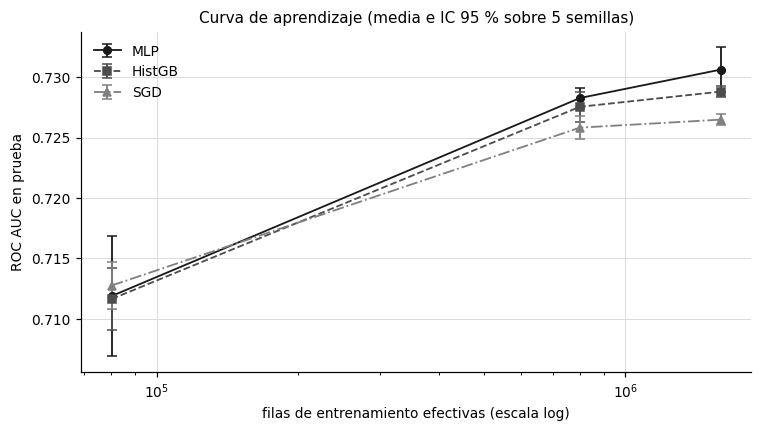

In [4]:
runs = pd.read_csv(ART / "sklearn" / "runs.csv")
runs["n_efectivo"] = runs["tier"].map(efectivo)
fig, ax = new_figure((7, 4))
estilos = series_styles(3)
for (m, nom), st in zip(nombres.items(), estilos):
    g = runs[runs["model"] == m].groupby("n_efectivo")["roc_auc"]
    mu, sd = g.mean(), g.std()
    half = 2.776 * sd / np.sqrt(5)
    ax.errorbar(mu.index, mu.values, yerr=half.values, label=nom, color=st["color"], linestyle=st["linestyle"],
                marker=st["marker"], capsize=3, linewidth=1.2, markersize=5)
ax.set_xscale("log"); ax.set_xlabel("filas de entrenamiento efectivas (escala log)"); ax.set_ylabel("ROC AUC en prueba")
ax.set_title("Curva de aprendizaje (media e IC 95 % sobre 5 semillas)", fontsize=10)
ax.legend(frameon=False); plt.tight_layout(); plt.show()

**Interpretación.** Los tres modelos mejoran con el volumen, con rendimientos decrecientes. Al pasar de 80.085 a 800.847 filas, el AUC del MLP sube de 0,7119 a 0,7283 (1,6 puntos), y al pasar a 1.601.694 sube a 0,7306 (0,2 puntos más). HistGB sigue la misma forma (0,7116, 0,7276 y 0,7288) y SGD también (0,7128, 0,7258 y 0,7265). Con 80 mil filas los tres modelos están empatados en 0,712 a 0,713, con intervalos que se traslapan; con 1,6 millones el MLP queda arriba, seguido de HistGB y de SGD.

Lo anterior indica una curva de aprendizaje de tipo potencia, donde cada vez que se multiplica el volumen por 10 la ganancia es menor. La forma en que se ordenan los modelos tiene una lectura clara: con pocos datos la capacidad extra del MLP no se aprovecha y la regresión logística rinde igual, y a medida que crece el volumen el MLP y el árbol potenciado empiezan a capturar interacciones que el modelo lineal no puede representar. La variabilidad entre semillas también baja con el volumen: la desviación estándar del AUC del MLP pasa de 0,0040 con 80 mil filas a 0,0015 con 1,6 millones.

Por tanto, corresponde comparar los modelos en el tier mayor, donde las diferencias son más estables, y con la cautela de que la ganancia de 1,6 puntos entre el primer y el segundo tier no se repetirá entre el segundo y el tercero. Si la curva sigue la misma forma, duplicar de nuevo los datos aportaría del orden de dos décimas de punto, un resultado relevante para la pregunta sobre cuándo vale la pena escalar con Spark.

## 4.5 Costo de ajuste según el volumen

El tiempo de ajuste se modela como $t(n) = a\, n^{b}$, de modo que $\log t = \log a + b \log n$. El exponente $b$, estimado por mínimos cuadrados sobre las medias de cada tier, resume la complejidad empírica: $b = 1$ indica costo lineal en el número de filas. La tabla reporta el tiempo medio de ajuste sobre las 5 semillas y su desviación estándar en los dos tiers mayores.

In [5]:
rows = []
for m, nom in nombres.items():
    g = runs[runs["model"] == m].groupby("n_efectivo")["fit_time_s"]
    mu, sd = g.mean(), g.std()
    b, loga = np.polyfit(np.log(mu.index.values), np.log(mu.values), 1)
    rows.append((nom, mu.iloc[0], mu.iloc[1], sd.iloc[1], mu.iloc[2], sd.iloc[2], b))
tabla(pd.DataFrame(rows, columns=["modelo", "t con 80.085 (s)", "t con 800.847 (s)", "DE con 800.847", "t con 1.601.694 (s)",
                                  "DE con 1.601.694", "exponente b"]), d=2)

modelo,t con 80.085 (s),t con 800.847 (s),DE con 800.847,t con 1.601.694 (s),DE con 1.601.694,exponente b
MLP,"18,36","269,07","78,18","330,50","86,57","1,02"
HistGB,"1,46","6,44","1,48","14,54","5,06","0,74"
SGD,"1,77","16,66","2,23","28,10","6,37","0,94"


**Interpretación.** El MLP es el modelo más costoso por un orden de magnitud: tarda en promedio 18,4 segundos con 80 mil filas, 269 con 800 mil y 330 con 1,6 millones, frente a 1,8, 16,7 y 28,1 segundos de SGD y 1,5, 6,4 y 14,5 de HistGB. Los exponentes empíricos son 1,02 para el MLP, 0,94 para SGD y 0,74 para HistGB: el costo crece de forma aproximadamente lineal con el número de filas en el MLP y en SGD, como corresponde a métodos que recorren los datos un número acotado de veces, y de forma sublineal en HistGB.

En ese sentido, el costo del MLP no viene de una complejidad peor que lineal, sino de la constante: cada época recorre una matriz de 4.110 columnas a través de una capa de 50 neuronas, y la parada temprana necesita varias épocas para estabilizarse. Así mismo, la desviación estándar del tiempo del MLP es alta (78 y 87 segundos en los dos tiers mayores), porque el número de épocas hasta la parada temprana cambia con la semilla. HistGB tiene el exponente más bajo porque construye histogramas de pocas columnas densas, y su costo depende más del número de árboles que del de filas.

Por lo anterior, conviene leer la ganancia del MLP frente a sus líneas base en relación con su costo: con 1,6 millones de filas, el MLP mejora el AUC de HistGB en 0,0018 a cambio de unas 23 veces más tiempo de ajuste. El capítulo 6 determina si esa diferencia es estadísticamente distinguible y si es relevante frente al margen $\delta = 0{,}01$.